In [42]:
import os, h5py
import numpy as np
import matplotlib.pyplot as plt
import sys
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
import scprinter as scp
import scprinter.tools as _sct
from concurrent.futures import Future
import h5py
class _SerialExecutor:
    def __init__(self, *args, **kwargs): pass
    def submit(self, fn, *args, **kwargs):
        f = Future()
        try:
            f.set_result(fn(*args, **kwargs))
        except Exception as e:
            f.set_exception(e)
        return f
    def shutdown(self, *args, **kwargs): pass
    def __enter__(self): return self
    def __exit__(self, *exc): self.shutdown()

_sct.ProcessPoolExecutor = _SerialExecutor
import time
import pandas as pd
import numpy as np
import pybedtools
import matplotlib.pyplot as plt
import os
import re
import math
import copy
import pyBigWig
from tqdm import tqdm
from zipfile import ZipFile
import seaborn as sns
import scipy.stats as ss

## HELPFUL LINKS
**tutorials:** https://ruochiz.com/scprinter_doc/tutorials/index.html \
**API:** https://ruochiz.com/scprinter_doc/reference/index.html 

In [43]:
wd = os.path.expanduser("~/scprinter_tutorial/CTCF_degron_tutorial")

In [44]:
n_jobs = max(1, os.cpu_count() - 2)
print("cores:", n_jobs)

cores: 8


In [45]:
#set barcodes
barcodes = ['ENCFF712GEL_ENCFF858VWC_CTCF_Un_Rep1_S1',
 'ENCFF668ATD_ENCFF582TRW_CTCF_Treated_Rep1_S1',
 'ENCFF364WVP_ENCFF680DCL_CTCF_Un_Rep2_S1',
 'ENCFF308LPR_ENCFF584DFW_CTCF_Treated_Rep2_S1']


### Fragment File Format:

lists every piece of DNA that Tn5 cut out and that got sequenced, one fragment per line. Each fragment is the stretch of DNA between two Tn5 cuts (two insertion sites: one at start and one at end).

| Col | Content |
| --- | --- |
| chrom | chromosome the fragment maps to2 |
| start | fragment start 0 indexed |
| end | fragment end 0 indexed |
| barcode | cell/sample that frag came from |
| count | times this exact fragment was seen |

#### Fragment lengths?

Under ~147 bp: nucleosome-free DNA, e.g. open regions around TF sites\
~200 bp, ~400 bp, …: DNA wrapped around 1 or 2 nucleosomes


In [46]:
#initialize
h5ad_path = os.path.join(wd, 'printer_data.h5ad')
done_flag = os.path.join(wd, 'printer_data.DONE') 

if os.path.exists(done_flag):
    print("Loading existing printer object...")
    printer = scp.load_printer(h5ad_path, scp.genome.hg38)
else:
    print("Importing fragments (first run, this takes a while)...")
    if os.path.exists(h5ad_path):
        os.remove(h5ad_path)            # clear any half-written file from an interrupted run
    printer = scp.pp.import_fragments(
        path_to_frags=os.path.join(wd, 'all.frags.tsv.gz'),
        barcodes=barcodes,
        savename=h5ad_path,
        genome=scp.genome.hg38,
        sorted_by_barcode=True)
    open(done_flag, 'w').close()        # mark as finished

printer.load_disp_model()

Loading existing printer object...
loading example_sites /Users/cherylxiang/scprinter_tutorial/CTCF_degron_tutorial/printer_data_supp/example_sites.h5ad
loading trial_footprints /Users/cherylxiang/scprinter_tutorial/CTCF_degron_tutorial/printer_data_supp/trial_footprints.h5ad


**see if you can figure out how they implement the background Tn5 insertion bias pattern implemented on the human genome**

- scprinter includes a neural net `Tn5_NN_model` built in pytorch that predicts Tn5’s cutting preference from DNA sequence.
- mdl looks at ±50 bp of sequence (one-hot encoded A/C/G/T) of each base, and predicts how readily Tn5 would cut there 
    - this is only based on the sequence itself, proteins are ignored
- NN is run over the genome once (for this its the hg38 genome--to my understanding this is a reference genome used to align short read samples?)

**FUNCTION**
`scp.genome.predict_genome_tn5_bias(fa_file="my_genome.fa", save_name="my_genome_bias.h5", device="cpu")`

- optional arg to use your own model, but defaults to its own
- pretty sure you can run any genome file through it?

**MODEL ARCHITECTURE**
```
print("Training Tn5 bias model")
    inputs = Input(shape = (np.shape(test_data[0])))
    conv_1 = Conv1D(32, 5, padding = 'same', activation = 'relu', strides = 1)(inputs)
    maxpool_1 = MaxPooling1D()(conv_1)
    conv_2 = Conv1D(32, 5, padding = 'same', activation = 'relu', strides = 1)(maxpool_1)
    maxpool_2 = MaxPooling1D()(conv_2)
    conv_3 = Conv1D(32, 5, padding = 'same', activation = 'relu', strides = 1)(maxpool_2)
    maxpool_3 = MaxPooling1D()(conv_3)
    flat = Flatten()(maxpool_3)
    fc = Dense(32,activation = "relu")(flat)
    out = Dense(1,activation = "linear")(fc)
    model = Model(inputs=inputs,outputs=out)  
    model.summary()
    model.compile(loss='mean_squared_error', optimizer='adam', metrics=['mse'])

```

In [47]:
# create barcode grouping using barcode col in fragments file
barcode_groups = pd.DataFrame([barcodes, np.arange(4)]).T
barcode_groups.columns = ['barcode','group']
grouping, unique_groups = scp.utils.df2cell_grouping(printer, barcode_groups)
barcode_groups

,barcode,group
0,ENCFF712GEL_ENCFF858VWC_CTCF_Un_Rep1_S1,0
1,ENCFF668ATD_ENCFF582TRW_CTCF_Treated_Rep1_S1,1
2,ENCFF364WVP_ENCFF680DCL_CTCF_Un_Rep2_S1,2
3,ENCFF308LPR_ENCFF584DFW_CTCF_Treated_Rep2_S1,3


In [48]:
#set genomic region for the single-region footprint
chrom, center = "chr1", 225845973 
start, end = center - 500, center + 500
region = f'{chrom}:{start}-{end}'

In [49]:
t0 = time.time()
scp.tl.get_footprint_score(
    printer,
    grouping,
    unique_groups,
    region,
    modes=np.arange(2, 101),
    footprintRadius=None,
    flankRadius=None,
    n_jobs=1,
    save_key="trial_footprints",
    backed=True,
    overwrite=True)
print ("takes", time.time()-t0)

estimated file size: 0.00 GB
Creating trial_footprints in printer.footprintsadata
obs=groups, var=regions
4000 100
Loading insertion profiles


collecting multi-scale footprints: 100%|██████████| 99/99 [00:12<00:00,  7.96it/s]


takes 126.23501086235046


regions stored: ['chr1:225845473-225846473']
shape: (4, 99, 1000)


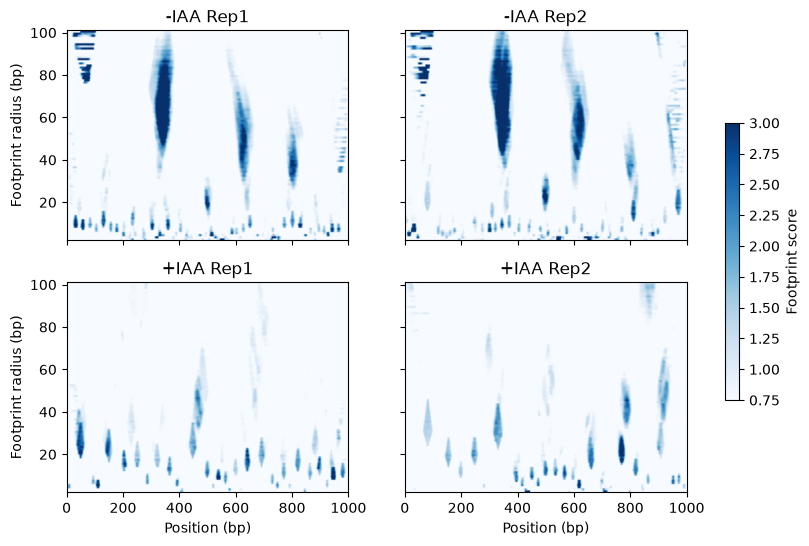

In [50]:
# --- load the footprints ---
fp_path = os.path.join(printer.file_path, "trial_footprints.h5ad")
with h5py.File(fp_path, "r", locking=False) as f:
    ids = list(f["obsm"].keys())
    print("regions stored:", ids)
    fp = f["obsm"][ids[0]][:]
print("shape:", fp.shape)   # (4, n_scales, 1000)

# --- plot ---
samples = ["-IAA Rep1", "+IAA Rep1", "-IAA Rep2", "+IAA Rep2"]   # groups 0-3
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
for k, ax in enumerate(axes.T.ravel()):        # column-major, matching the tutorial layout
    im = ax.imshow(fp[k], aspect="auto", origin="lower", cmap="Blues", vmin=0.75, vmax=3.0,
                   extent=[0, fp.shape[2], 2, 2 + fp.shape[1]])
    ax.set_title(samples[k])
axes[1, 0].set_xlabel("Position (bp)"); axes[1, 1].set_xlabel("Position (bp)")
axes[0, 0].set_ylabel("Footprint radius (bp)"); axes[1, 0].set_ylabel("Footprint radius (bp)")
fig.colorbar(im, ax=axes, shrink=0.6, label="Footprint score")
plt.show()

**there should be 2 conditions: 1 with the CTCF-degrading (degron) drug, and 1 without any drug.**

Testing other sites?

In [51]:
# Pre-filtered CTCF sites from the Zenodo download:
# accessible, lose CTCF with the degron drug, sorted strongest first.
# (Same result as tutorial cells 10–12, without the memory-heavy computation.)
CTCF_bed_filt = pd.read_table(os.path.join(wd, "CTCF_unibind_filt.bed"), header=None)
print(len(CTCF_bed_filt), "sites")   # ~1,147
CTCF_bed_filt.head()

1147 sites


,0,1,2,3,4,5
0,chr20,33096172,33096191,CTCF_CAGCCAGCAGGTGGACCCC,86.6,+
1,chr6,116268668,116268687,CTCF_TATCCCCTAGAGGGAGGTA,86.1,+
2,chr1,85308297,85308316,CTCF_AGCCCACCAGGGGGCAGCG,89.7,+
3,chr8,144805193,144805212,CTCF_GGGCCACTAGAGGGCTCCT,89.6,-
4,chr21,36977191,36977210,CTCF_CGTCCAGCAGAGGGGAGTG,84.7,+


In [52]:
n_sites = 4                                   
sites = CTCF_bed_filt.iloc[:n_sites]           # strongest CTCF sites that lose binding after degron
regions, strands = [], []
for _, row in sites.iterrows():
    c = (int(row[1]) + int(row[2])) // 2
    regions.append(f"{row[0]}:{c-500}-{c+500}")
    strands.append(row[5])
print(regions)

cond_groups = pd.DataFrame({"barcode": barcodes,
                            "group": ["no_drug", "degron", "no_drug", "degron"]})
grouping2, groups2 = scp.utils.df2cell_grouping(printer, cond_groups)
print(groups2)                                 # ['degron' 'no_drug'] (sorted alphabetically)

['chr20:33095681-33096681', 'chr6:116268177-116269177', 'chr1:85307806-85308806', 'chr8:144804702-144805702']
['degron' 'no_drug']


In [53]:
t0 = time.time()
scp.tl.get_footprint_score(printer, grouping2, groups2, regions,
    modes=np.arange(2, 101), footprintRadius=None, flankRadius=None,
    n_jobs=1, save_key="example_sites", backed=True, overwrite=True)
print("takes", time.time() - t0)

estimated file size: 0.00 GB
Creating example_sites in printer.footprintsadata
obs=groups, var=regions
8000 100


collecting multi-scale footprints: 100%|██████████| 396/396 [00:10<00:00, 39.09it/s]


takes 64.83205199241638


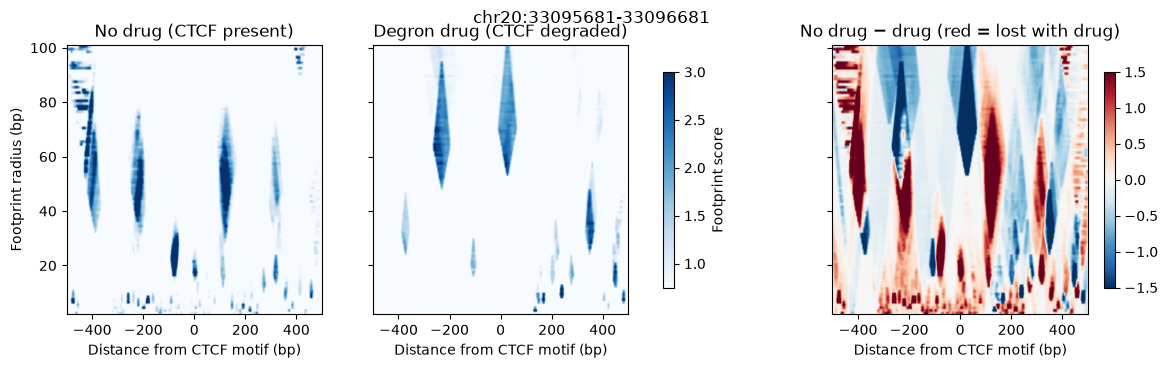

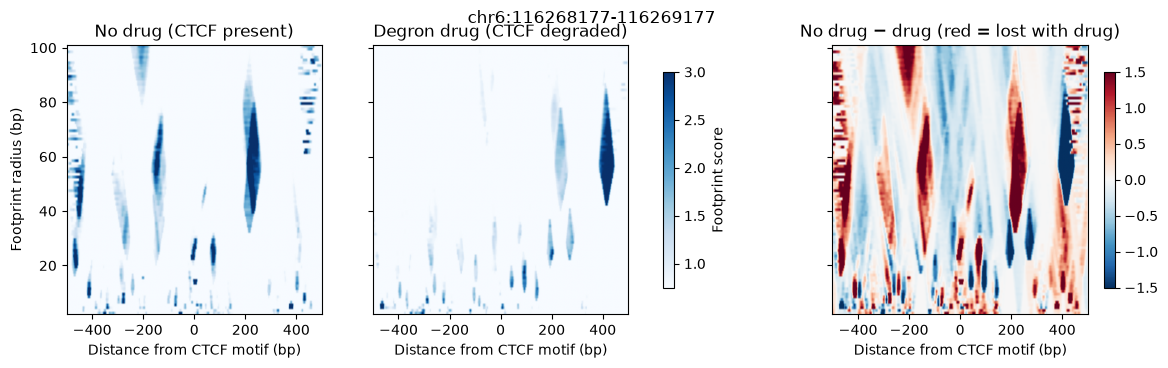

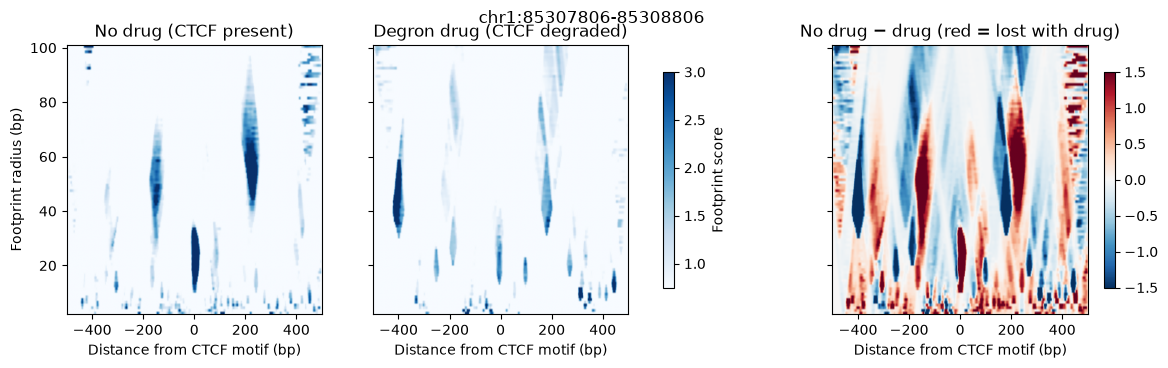

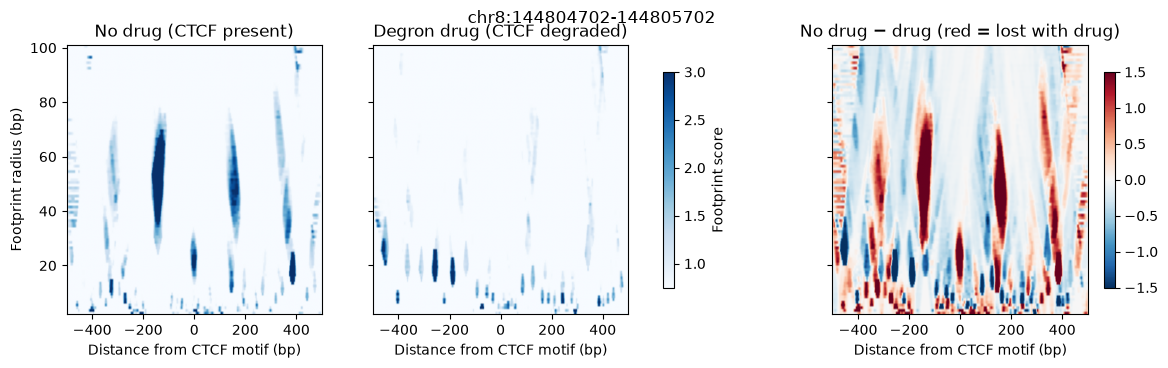

In [54]:
fp_path = os.path.join(printer.file_path, "example_sites.h5ad")
i_no, i_deg = list(groups2).index("no_drug"), list(groups2).index("degron")

with h5py.File(fp_path, "r", locking=False) as f:
    for reg, strand in zip(regions, strands):
        fp = f["obsm"][reg][:]                          # (2 groups, 99 scales, 1000 bp)
        if strand == "-":
            fp = fp[:, :, ::-1]                          # orient all motifs the same way
        no, deg = fp[i_no], fp[i_deg]

        fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
        ext = [-500, 500, 2, 101]
        for ax, data, title in [(axes[0], no, "No drug (CTCF present)"),
                                (axes[1], deg, "Degron drug (CTCF degraded)")]:
            im = ax.imshow(data, aspect="auto", origin="lower", cmap="Blues",
                           vmin=0.75, vmax=3.0, extent=ext)
            ax.set_title(title)
        fig.colorbar(im, ax=axes[:2], shrink=0.8, label="Footprint score")
        d = axes[2].imshow(no - deg, aspect="auto", origin="lower", cmap="RdBu_r",
                           vmin=-1.5, vmax=1.5, extent=ext)
        axes[2].set_title("No drug − drug (red = lost with drug)")
        fig.colorbar(d, ax=axes[2], shrink=0.8)
        for ax in axes: ax.set_xlabel("Distance from CTCF motif (bp)")
        axes[0].set_ylabel("Footprint radius (bp)")
        fig.suptitle(reg); plt.show()

In [55]:
printer.close()

#deletes damaged files

import os
wd = os.path.expanduser("~/scprinter_tutorial/CTCF_degron_tutorial")
for f in ["printer_data.h5ad", "printer_data.DONE", "trial_footprints.h5ad"]:
    p = os.path.join(wd, f)
    if os.path.exists(p):
        os.remove(p); print("removed", f)